# Healthcare insurance analysis
Unit 1: Data Analytics and Python for Data Preparation

This project looks at how recorded charges differ by smoking status, age, BMI and region. OpenAI Codex helped with the code and writing. Further AI-use details are in [the project record](../evidence/ai_use.md).

## Task 1: Business case (1.1–1.2)
The audience is a finance or planning team. One overall average may hide large differences, so the questions are:
1. How do charges differ between smokers and non-smokers?
2. How are age and BMI related to charges?
3. How do charges compare across regions?

### How the applications support decisions (1.1)
AHRQ describes healthcare data being used to study costs, service use and treatment outcomes [2]. The following are practical examples of those applications, rather than findings from this CSV.

- **Budget planning:** A planning team could combine dated charges with membership totals to estimate spending per member and identify where more resources may be needed. For example, rising service use could prompt a review of next year's budget. This supports resource allocation, but changes in prices or membership can make past averages misleading.
- **Comparing groups:** Managers could compare charges within age or health-condition groups to decide which differences need investigation. For example, a higher regional average might reflect a different mix of patients. CMS explains why stratification and adjustment help comparisons account for population differences [3]. This CSV allows smoking-group comparisons, but lacks diagnoses for fuller adjustment.
- **Reviewing services:** An insurer could compare costs and outcomes before and after a support programme to decide whether to continue funding it. This needs treatment dates, outcomes and a suitable comparison group. It can inform service decisions, but differences in participants' starting health may distort the result. This CSV cannot establish programme effectiveness.

### Planning rationale (1.2)
The specific challenge is that one overall charge average may hide differences relevant to expense planning. Finance managers need the size and spread of charges; operations managers need to know which groups merit further investigation. Counts, medians and comparisons within smoking groups support those needs without treating a high average as evidence of poor performance.

Interpretability is a key data challenge: regional differences may reflect the people in each group rather than location itself. The opportunity is to use the dashboard to inspect those differences before requesting more detailed claims data. AI can help draft grouping code and plain-language explanations. Its numbers must be checked against Python outputs, and its recommendations must stay within the dataset's limits; improved planning is a proposed benefit, not a measured outcome.


## Task 2: Load and prepare the data (2.1, 2.3)
Run the cells in order from the project folder (`DA Unit 1`) or its `notebooks` folder. Install the packages listed in `requirements.txt` in the project environment.

The CSV comes from Kaggle's Healthcare Insurance dataset [1], downloaded on 27 October 2026. The raw file is kept separately from the cleaned copy.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

project_root = Path.cwd()
if not (project_root / "data/raw/insurance.csv").is_file():
    project_root = project_root.parent
if not (project_root / "data/raw/insurance.csv").is_file():
    raise FileNotFoundError("Open the notebook from the project root or notebooks folder.")

insurance = pd.read_csv(project_root / "data/raw/insurance.csv")
print("Rows and columns:", insurance.shape)
insurance.head()

/Users/mmv/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/w8/gfpcq2yx3pqf8g7klkl281gr0000gn/T/matplotlib-z9urio7n because there was an issue with the default path (/Users/mmv/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


Rows and columns: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Check the data
Check column types, missing values, repeated rows and the range of numeric values.

In [2]:
insurance.info()
print("Missing values:")
print(insurance.isna().sum())
print("Repeated rows:", insurance.duplicated().sum())
insurance.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Repeated rows: 1


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


In [3]:
for column in ["sex", "smoker", "region"]:
    print(column, insurance[column].unique())

insurance.loc[insurance.duplicated(keep=False)]

sex <ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
smoker <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
region <ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


### Cleaning decisions
There are no missing values to fill. One row repeats, but there is no ID to prove it is the same person, so both rows are kept. High charges are also kept because they may be real.

The categories already have consistent labels. No numeric encoding is needed for this analysis. Age bands make comparisons easier; they are reporting groups, not medical categories.

In [4]:
cleaned = insurance.copy()

cleaned["age_band"] = pd.cut(
    cleaned["age"],
    bins=[18, 30, 45, 60, 65],
    labels=["18-29", "30-44", "45-59", "60-64"],
    right=False
)

print("Negative charges:", (cleaned["charges"] < 0).sum())
print("BMI at or below zero:", (cleaned["bmi"] <= 0).sum())
print("Negative dependants:", (cleaned["children"] < 0).sum())
print("Rows without an age band:", cleaned["age_band"].isna().sum())
cleaned.head()

Negative charges: 0
BMI at or below zero: 0
Negative dependants: 0
Rows without an age band: 0


,age,sex,bmi,children,smoker,region,charges,age_band
0,19,female,27.900,0,yes,southwest,16884.92400,18-29
1,18,male,33.770,1,no,southeast,1725.55230,18-29
2,28,male,33.000,3,no,southeast,4449.46200,18-29
3,33,male,22.705,0,no,northwest,21984.47061,30-44
4,32,male,28.880,0,no,northwest,3866.85520,30-44


In [5]:
cleaned.to_csv(project_root / "data/processed/insurance_cleaned.csv", index=False)
reloaded = pd.read_csv(project_root / "data/processed/insurance_cleaned.csv")

print("Rows before and after:", len(insurance), len(reloaded))
print("Missing values after saving:", reloaded.isna().sum().sum())
print("Saved values match:", cleaned.astype(str).equals(reloaded.astype(str)))

Rows before and after: 1338 1338
Missing values after saving: 0
Saved values match: True


### Overall charges
The mean includes every value. The median is the middle value and is less affected by very high charges. The currency and time period are not confirmed by the source.

Mean: 13270.42
Median: 9382.03
Standard deviation: 12110.01


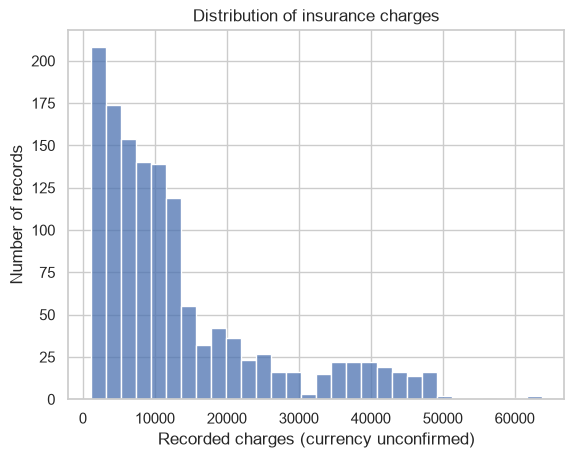

In [6]:
print("Mean:", round(np.mean(cleaned["charges"]), 2))
print("Median:", round(np.median(cleaned["charges"]), 2))
print("Standard deviation:", round(np.std(cleaned["charges"], ddof=1), 2))

sns.histplot(data=cleaned, x="charges", bins=30)
plt.title("Distribution of insurance charges")
plt.xlabel("Recorded charges (currency unconfirmed)")
plt.ylabel("Number of records")
plt.show()

The mean is 13,270.42 and the median is 9,382.03. A smaller number of high charges pulls the mean upwards.

### Distribution shape: skewness and kurtosis (2.1, 3.3)
Skewness describes asymmetry: positive values indicate asymmetry towards high charges and negative values towards low charges. Excess kurtosis describes the weight in extreme deviations relative to a normal-distribution reference of zero. It does not simply describe how tall a peak looks. Both are sample-adjusted estimates; small selections and extreme records can strongly affect them.

The histogram uses 30 equal-width intervals and counts records in each. Its dashed median line appears in the dashboard; the original notebook histogram above has no reference line. A positive overall skew can combine different subgroup shapes, so compare the pooled results with each smoking group rather than assuming one bell-shaped distribution.

In [7]:
shape_rows = []
for label, values in [
    ("All records", cleaned["charges"]),
    ("Non-smokers", cleaned.loc[cleaned["smoker"] == "no", "charges"]),
    ("Smokers", cleaned.loc[cleaned["smoker"] == "yes", "charges"]),
]:
    shape_rows.append({"Group": label, "Records": len(values),
                       "Skewness": values.skew(), "Excess kurtosis": values.kurt()})
display(pd.DataFrame(shape_rows).set_index("Group").round(2))

,Records,Skewness,Excess kurtosis
Group,,,
All records,1338,1.52,1.61
Non-smokers,1064,1.54,3.15
Smokers,274,0.13,-1.04


Overall charges are right-skewed (1.52), with positive excess kurtosis (1.61). Many records occupy the lower charge intervals, while relatively few high charges extend the right tail. The mean is pulled above the median. Non-smokers are also right-skewed (1.54), with greater excess kurtosis (3.15); smokers have much lower overall asymmetry (0.13) and negative excess kurtosis (−1.04). Near-zero skew does not imply a normal or single-peaked distribution. These measures explain the observed sample, not causes or future costs.

The smoking box plots show the median, middle 50% and whiskers, rather than the frequency of each charge interval. Non-smokers have 46 observations above their upper 1.5 × IQR fence; smokers have none beyond either fence. This does not mean smokers have no high charges: each group has its own quartiles and spread. All flagged observations are retained.

Definitions: [pandas skewness](https://pandas.pydata.org/docs/reference/api/pandas.Series.skew.html) and [Fisher excess kurtosis](https://pandas.pydata.org/docs/reference/api/pandas.Series.kurt.html).

### Question 1: Smoking status

In [8]:
smoking_summary = cleaned.groupby("smoker")["charges"].agg(["count", "mean", "median"])
smoking_summary.round(2)

,count,mean,median
smoker,,,
no,1064,8434.27,7345.41
yes,274,32050.23,34456.35


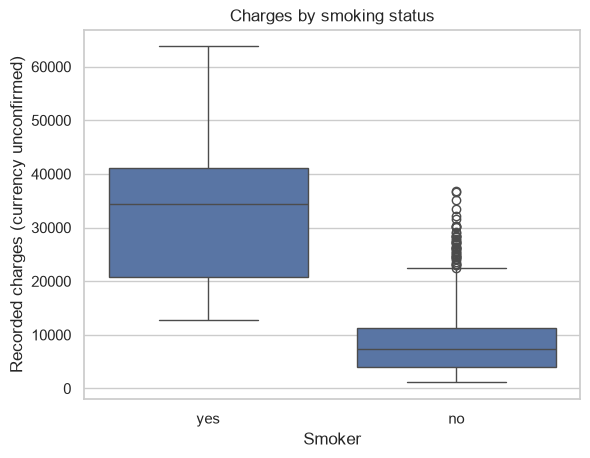

In [9]:
sns.boxplot(data=cleaned, x="smoker", y="charges")
plt.title("Charges by smoking status")
plt.xlabel("Smoker")
plt.ylabel("Recorded charges (currency unconfirmed)")
plt.show()

Mean charges are 32,050.23 for smokers (274 records) and 8,434.27 for non-smokers (1,064 records). Smokers also have a higher median. This is a relationship in the sample; it does not prove smoking caused the whole difference.

### Question 2: Age and BMI

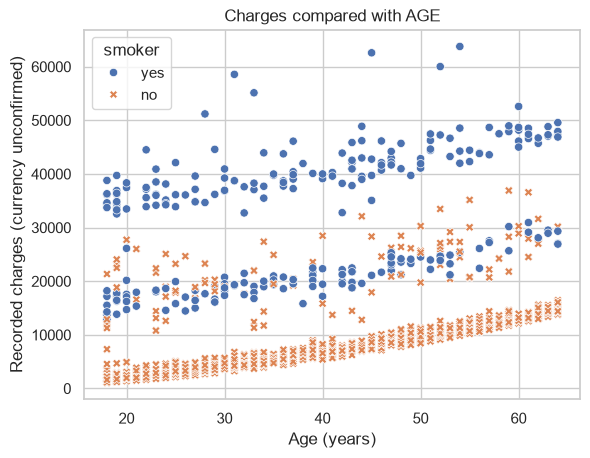

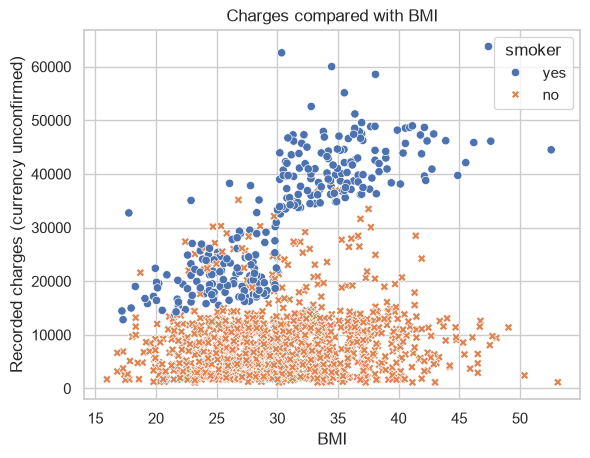

,age,bmi,children,charges
age,1.000,0.109,0.042,0.299
bmi,0.109,1.000,0.013,0.198
children,0.042,0.013,1.000,0.068
charges,0.299,0.198,0.068,1.000


In [10]:
for column in ["age", "bmi"]:
    sns.scatterplot(data=cleaned, x=column, y="charges", hue="smoker", style="smoker")
    plt.title("Charges compared with " + column.upper())
    plt.xlabel("Age (years)" if column == "age" else "BMI")
    plt.ylabel("Recorded charges (currency unconfirmed)")
    plt.show()

cleaned[["age", "bmi", "children", "charges"]].corr().round(3)

In [11]:
# Compare the relationships within each smoking group.
for group in ["no", "yes"]:
    print("Smoker:", group)
    group_data = cleaned.loc[cleaned["smoker"] == group]
    print(group_data[["age", "bmi", "charges"]].corr()["charges"].round(3))

Smoker: no
age        0.628
bmi        0.084
charges    1.000
Name: charges, dtype: float64
Smoker: yes
age        0.368
bmi        0.806
charges    1.000
Name: charges, dtype: float64


Age and charges have a positive correlation of 0.299. BMI has a weaker overall correlation of 0.198, but its relationship with charges is stronger in the smoking group. The scatter plots show why looking at separate groups helps. Correlation alone does not explain the cause.

### Question 3: Regions

,count,mean,median
region,,,
northeast,324,13406.38,10057.65
northwest,325,12417.58,8965.80
southeast,364,14735.41,9294.13
southwest,325,12346.94,8798.59


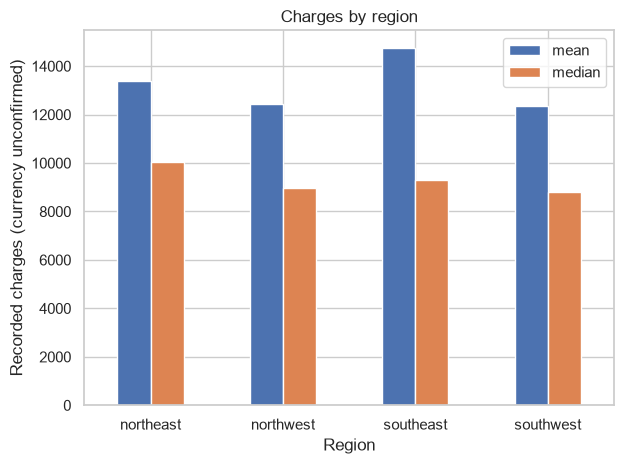

count      mean
region    smoker                 
northeast no        257   9165.53
          yes        67  29673.54
northwest no        267   8556.46
          yes        58  30192.00
southeast no        273   8032.22
          yes        91  34845.00
southwest no        267   8019.28
          yes        58  32269.06

In [12]:
region_summary = cleaned.groupby("region")["charges"].agg(["count", "mean", "median"])
display(region_summary.round(2))

region_summary[["mean", "median"]].plot(kind="bar", rot=0)
plt.title("Charges by region")
plt.xlabel("Region")
plt.ylabel("Recorded charges (currency unconfirmed)")
plt.tight_layout()
plt.show()

cleaned.groupby(["region", "smoker"])["charges"].agg(["count", "mean"]).round(2)

Southeast has the highest overall mean, while southwest has the lowest. Southeast does not have the highest mean among non-smokers, so the overall ranking gives an incomplete picture. Differences in age, smoking and health needs could affect the comparison.

### Selection and age groups (2.1)
This selects non-smokers aged 60 or over, then compares charges across the age bands.

In [13]:
cleaned.loc[
    (cleaned["age"] >= 60) & (cleaned["smoker"] == "no"),
    ["age", "bmi", "region", "charges"]
].head()

,age,bmi,region,charges
9,60,25.840,northwest,28923.13692
20,60,36.005,northeast,13228.84695
26,63,23.085,northeast,14451.83515
33,63,28.310,northwest,13770.09790
36,62,32.965,northwest,15612.19335


In [14]:
cleaned.groupby("age_band", observed=True)["charges"].agg(["count", "mean"]).round(2)

,count,mean
age_band,,
18-29,417,9182.49
30-44,392,12490.91
45-59,415,15922.93
60-64,114,21248.02


### Dashboard comparisons and validation (2.1, 2.3, 3.2)
The dashboard adds sex comparisons within smoking groups, mean/median charges by number of children, and separate BMI trend lines. The following tables and checks connect these additions to the notebook. Its USD and BMI kg/m² labels are display assumptions, not source-confirmed units; no values are converted.

The sex comparison reverses direction across smoking groups. Charges do not rise consistently with number of children, and the smallest categories need caution. The BMI lines summarise linear associations within each smoking group; they are not validated forecasts or causal effects.

count      mean    median
smoker sex                              
no     female    547   8762.30   7639.42
       male      517   8087.20   6985.51
yes    female    115  30679.00  28950.47
       male      159  33042.01  36085.22

,count,mean,median
children,,,
0,574,12365.98,9856.95
1,324,12731.17,8483.87
2,240,15073.56,9264.98
3,157,15355.32,10600.55
4,25,13850.66,11033.66
5,18,8786.04,8589.57


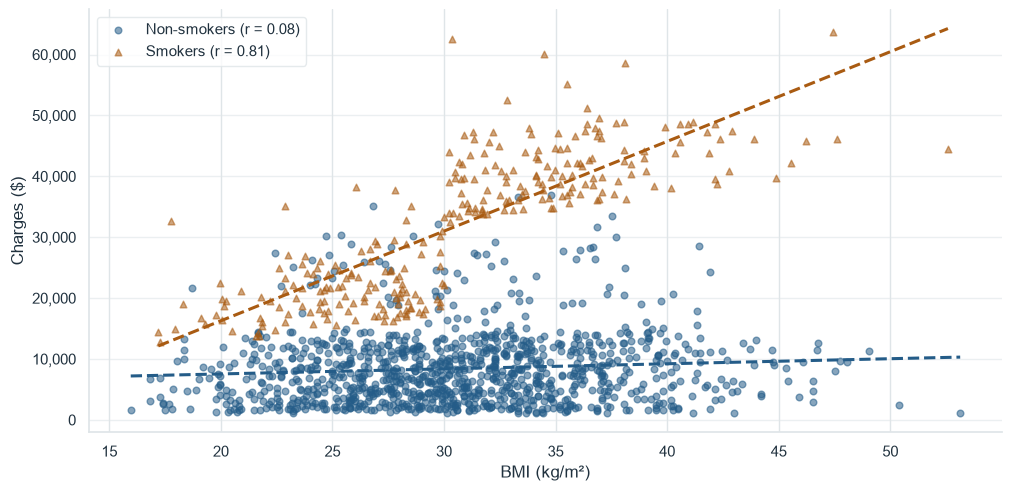

box: Smokers’ median charges are 34,456 USD versus 7,345 USD for non-smokers. Smokers’ IQR is 2.74 times as large; the middle-50% ranges do not overlap. Upper outliers: 46 among non-smokers and 0 among smokers, using each group’s own cutoff.
hist: Positive skew (1.52): a tail towards higher charges. Positive kurtosis (1.61): greater weight in extreme deviations relative to the normal reference.
smokingcomparison: Smokers have higher mean charges by 23,616 USD (smokers/non-smokers: 3.80 times). The median is also higher among smokers by 27,111 USD.
regionchart: Mean charges span 2,388 USD across regions; Southeast has the highest mean and Southwest the lowest. Northeast has the highest median.
agechart: Age has a positive overall linear association with charges (r = 0.30). Within-group correlations are 0.63 among non-smokers and 0.37 among smokers.
bmichart: BMI has a positive overall linear association with charges (r = 0.20). Within-group correlations are 0.08 among non-smokers and 0.

In [15]:
import sys

# Allow the same shared dashboard functions from either notebook launch folder.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.analysis import validate, summary
from src.report import explanations, report_chart

validate(cleaned)
sex_groups = cleaned.groupby(["smoker", "sex"])["charges"].agg(["count", "mean", "median"])
children_groups = cleaned.groupby("children")["charges"].agg(["count", "mean", "median"])
display(sex_groups.round(2))
display(children_groups.round(2))
assert sex_groups["count"].sum() == children_groups["count"].sum() == len(cleaned)

# Compare dashboard summaries with the direct notebook calculations.
pd.testing.assert_frame_equal(
    summary(cleaned, ["smoker", "sex"])[["count", "mean", "median"]], sex_groups
)
pd.testing.assert_frame_equal(
    summary(cleaned, "children")[["count", "mean", "median"]], children_groups
)
sex_means = sex_groups["mean"].unstack("sex")
assert sex_means.loc["no", "female"] > sex_means.loc["no", "male"]
assert sex_means.loc["yes", "male"] > sex_means.loc["yes", "female"]
assert not children_groups["mean"].is_monotonic_increasing

figure = report_chart(cleaned, "bmichart", dark=False)
for line, group in zip(figure.axes[0].lines, ["no", "yes"]):
    part = cleaned.loc[cleaned["smoker"] == group]
    slope, intercept = np.polyfit(part["bmi"], part["charges"], 1)
    x, y = line.get_data()
    np.testing.assert_allclose(y, slope * x + intercept)
plt.show()

# Retain the current full-sample chart explanations for the AI revision record.
for chart_name, text in explanations(cleaned).items():
    print(chart_name + ": " + text)
print("Dashboard group counts, summaries and BMI lines checked.")

### Predictive regression (2.1, 2.3, 3.3)
Can age, sex, BMI, children, smoking status and region help predict recorded charges for held-out sample records? This is an exploratory extension, not a current-cost forecast.

A fixed seed (42) assigns about 80% of distinct source records to training and 20% to testing. Exact duplicate rows stay together to avoid leakage; all rows are retained. A pipeline fits categorical encoding and ordinary least-squares regression on training data only. A BMI × smoking interaction is specified from the earlier exploratory findings, so the BMI slope can differ between smokers and non-smokers. Age bands and charges are excluded as predictors; age is used directly. There is no model search or test-set tuning.

The comparison is a baseline that predicts the **training median**, which suits MAE. Lower MAE means lower average absolute error, measured in the original, unconfirmed charge units. The held-out data is not used to fit coefficients or encoding. Because the full sample was explored before this extension, this is not a completely independent confirmation of model selection; external data would be needed for stronger validation.

Training records: 1070; test records: 268


,Model,Test MAE
0,Training-median baseline,7721.87
1,Linear regression + BMI/smoking interaction,2723.40


,records,mae
smoker,,
Non-smokers,223,2477.32
Smokers,45,3942.85


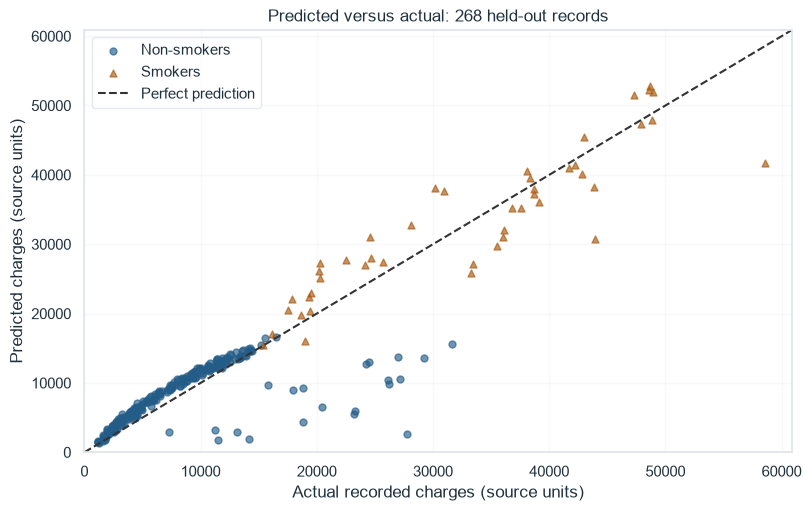

Estimates miss actual charges by 2,723.40 on average, versus 7,721.87 for the simple median estimate (64.7% lower error). Average error is 6,108 for the highest-charge quarter, compared with 1,595 for the remaining records.


In [16]:
from src.regression import regression_results, prediction_chart, interpretation

train, test, model_scores, test_predictions, group_errors = regression_results(cleaned)
print(f"Training records: {len(train)}; test records: {len(test)}")
display(model_scores.round(2))
display(group_errors.rename(index={"no": "Non-smokers", "yes": "Smokers"}).round(2))
figure = prediction_chart(test_predictions)
plt.show()
print(interpretation(model_scores, test_predictions))

The dashed line represents perfect predictions. Points above it are overestimates; points below it are underestimates. The spread around the line shows why the prediction should not be treated as an exact amount. Smoking-group MAEs help check uneven performance, but do not establish fairness across all groups.

Missing diagnoses, dates and sampling information limit generalisation. A single split gives an uncertain performance estimate; MAE is not a prediction interval. Linear slopes also simplify nonlinear relationships and may produce negative amounts. A future improvement would be training-only cross-validation and an external test set with dated claims. These predictions cannot establish causes, forecast current insurance budgets or justify individual premiums. No live pricing calculator is provided.

Method references: [scikit-learn grouped splitting](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html), [column preprocessing](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html) and [MAE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html).

### Code review (2.2)
Two changes improved the original analysis:

- `insurance.duplicated(False)` caused an error because `False` was treated as a column selection. Using `insurance.duplicated(keep=False)` correctly shows both matching rows. The duplicate count separately reports one repeat.
- Comparing regional means alone hid differences between groups. Adding medians, counts and a region-by-smoking table makes the comparison clearer. The tables can be checked against the total row count.

This notebook now uses direct pandas calculations and short plotting steps instead of importing the analysis from another file. The separate Streamlit dashboard uses reusable functions. Version history and project checks are recorded under `../evidence/`.

For the second improvement, the original calculation was `cleaned.groupby("region")["charges"].mean()`. The revised calculation uses `.agg(["count", "mean", "median"])` and a separate grouping by `["region", "smoker"]`, as shown above. The regional counts total 1,338. Southeast has the highest overall mean but not the highest non-smoker mean, demonstrating why the extra grouping changes the interpretation. `tests/test_analysis.py` also checks that smoking-group counts and their weighted mean reconcile with the full dataset.

The review also considered maintainability. Names such as `cleaned` and `smoking_summary` describe their purpose, while the age/BMI plotting loop avoids repeating the same plotting steps. Short comments explain decisions. The dashboard separates validation, filtering and chart functions so they can be reused and tested. Its loader catches file and validation errors and displays a message instead of continuing with unusable data. The notebook leaves errors visible for investigation.

The saved lint record reports a successful Ruff check for the Python files; it does not establish that notebook cells were linted. Existing tests cover raw-data preservation, reloads, invalid inputs and dashboard selections. Git separates source acquisition, ETL, notebook evidence and dashboard changes into meaningful commits, allowing each change to be inspected and earlier versions compared. The assessment revision is recorded separately from the earlier dashboard fixes. These changes improve correctness and clarity; no speed improvement is claimed.


## Task 3: AI use and findings (3.1–3.3)
Codex helped draft the analysis, code and explanations. The repeated-row check shows why generated code needs running. Suggestions to fill missing values or remove all high charges were not used because the data did not justify them. The original prompt, narrative draft and revisions are kept in [the AI-use record](../evidence/ai_use.md).

The management summary was revised to include group sizes, avoid claiming cause and effect, and state that the currency is unconfirmed.

**Summary for the planning team:** Charges vary widely. Smokers have higher average charges in this sample, and age and BMI show different patterns across smoking groups. Regional averages should be read alongside group sizes and medians. These results suggest areas to investigate, rather than a basis for setting individual premiums.

### AI decisions and checks (3.1)
Codex suits this task because it can suggest pandas expressions, explain errors and draft text alongside the project files. The original prompt, response and narrative revision are retained in the AI-use record. The duplicate-check correction was accepted after the revised expression identified both matching rows. Automatic imputation and deletion of high charges were rejected because there were no missing values and no evidence that the high charges were errors. The management draft was modified to add group sizes and avoid a causal claim; its figures were checked against Python summaries and independent raw-CSV calculations.

These are documented decisions from the AI-assisted workflow. They do not demonstrate the student's personal review. Before submission, the student needs to check the choices against the source and explain, in their own words, why the duplicate was retained, why regional averages need subgroup checks, and why these results cannot set individual premiums. Any resulting changes should be recorded in the AI-use record.


### Evaluation against the questions (3.3)
- **Smoking:** Answered descriptively. Both mean and median are higher among smokers. However, the groups contain 274 and 1,064 records, and differences in age or health could contribute. The comparison cannot estimate the effect of stopping smoking.
- **Age and BMI:** Answered for observed associations. BMI correlation is about 0.08 among non-smokers and 0.81 among smokers, so the overall correlation hides an important difference. Missing diagnoses and treatment information prevent a fuller explanation; a trend line cannot predict an individual's costs reliably.
- **Regions:** Answered as a comparison of this sample, but the explanation remains unresolved. Southeast has the highest overall mean, while northeast has the highest non-smoker mean. Separating smoking groups helps, but does not adjust for age, clinical needs or differences in regional coverage.

The workflow moved from profiling and justified preparation to descriptive summaries, plots and subgroup checks. A box plot adds spread that a mean-only bar chart loses, although bars are easier for comparing exact averages. The optional regression above extends the subgroup analysis using several characteristics and held-out validation. Its linear assumptions and single-split evaluation remain limitations; it does not prove causation.

Two practical lessons are to check group composition before interpreting an overall ranking, and to test generated code rather than trusting plausible wording. AI can miss these issues and cannot recover absent provenance. The next improvement is dated claims with membership denominators and relevant clinical information, acquired with permission, because these would support comparisons over time and fairer group analysis. These are workflow lessons; the student's personal reflection still needs their own review.


## Task 4: Data management (4.1–4.2)
### Data dictionary

| Field | Type | Meaning |
| --- | --- | --- |
| age | Integer | Age in years; observed range 18–64 |
| sex | Text | Source categories: female/male |
| bmi | Decimal | Body mass index; units not confirmed in the source |
| children | Integer | Number of covered dependants |
| smoker | Text | Source categories: yes/no |
| region | Text | Four regional labels; exact boundaries unconfirmed |
| charges | Decimal | Recorded insurance charges; currency and period unconfirmed |
| age_band | Category | Added age groups: 18–29, 30–44, 45–59, 60–64 |

### Storage and quality
This is secondary data downloaded as a CSV. The saved Kaggle metadata lists CC0 [1]. The workflow is: load the raw file, inspect it, add age bands, save a cleaned CSV and check the saved values. No source rows are removed.

CSV suits this small, single-file project because it is easy to read and share. A database would be more useful for larger linked claims tables, with access controls and checks on relationships.

| Quality area | Finding |
| --- | --- |
| Completeness | No missing source values |
| Consistency | Category labels are consistent |
| Validity | No negative charges/dependants or non-positive BMI; age bands cover all rows |
| Uniqueness | One repeated row; no ID to confirm duplication |
| Accuracy | Cannot check against original medical or financial records |
| Timeliness | Observation dates are unavailable |

Unexpected missing values, invalid values or changed columns should be investigated before continuing. A high charge alone is not enough reason to delete a record.

### Responsible handling
The file has no names or direct identifiers. It should not be linked to other files to identify people. Real health records would need restricted access, secure storage and sharing, and only the fields needed for the task. Retention should follow the organisation's policy.

Identifiable health data can require extra protection under UK data-protection rules [4]. CC0 concerns copyright and does not remove privacy responsibilities [5]. FHIR supports exchanging healthcare information [6], but this CSV is not a FHIR dataset.

The sample may not represent the wider population. Its limited categories and missing health information could lead to unfair conclusions. These comparisons should not be used alone to decide an individual's cover or price.

### Checks, failure actions and method choices (4.1–4.2)
The raw CSV is preserved as the starting point. The cleaned copy adds age bands without removing rows; the label-change record in `evidence/cleaning_changes.csv` reports zero changes for the three categorical fields. Reload checks establish that saving has preserved the values. The dashboard reads that cleaned file and applies the same validation rules before calculating its summaries.

| Check | Rule and action if it fails |
| --- | --- |
| Structure and completeness | Expect the seven source fields in their recorded order and no missing source values. Stop and investigate a changed schema or incomplete file; do not silently fill values. |
| Types and finite values | Numeric fields must contain finite numbers; age and children must be whole numbers. Reject invalid input and check the source before correcting it. |
| Ranges | Charges and children must be non-negative; BMI must be positive. Ages must lie within the documented 18–64 analysis scope. An age outside that scope requires reviewing the bands, not assuming the person is invalid. |
| Categories | Check sex, smoking and region against the recorded labels. Investigate unfamiliar labels before mapping them. |
| Saved output | Reconcile row counts, source values, group totals and summaries after reload. Investigate any mismatch before using the dashboard. |

These are reproducible project checks, not clinical accuracy tests. Retaining the uncertain duplicate is preferable to automatic removal without an identifier. Retaining high charges preserves the observed distribution; automatic trimming could understate expense variation. Leaving readable categories avoids suggesting that numeric codes measure a continuous relationship.

CSV is proportionate for 1,338 static records and makes the raw-to-clean process inspectable. A relational database would add useful constraints and controlled access for linked, changing claims, but would bring unnecessary administration here. Separate raw and processed folders make it easier to trace mistakes and regenerate outputs.

Only the licensed public sample belongs in the shared repository. Before sharing new data, check permission and identifiers; public availability alone does not prove consent or unrestricted reuse. For real health records, minimise collected fields, use authorised role-based access and protected storage, share through approved restricted channels, and follow a documented retention/deletion schedule. Public GitHub would be unsuitable for confidential records. These are proposed operational safeguards, not controls implemented by this demonstration. CC0 supports reuse of this published sample; it does not settle privacy or bias concerns.


## References and supporting work
1. [Kaggle: Healthcare Insurance](https://www.kaggle.com/datasets/willianoliveiragibin/healthcare-insurance) — dataset and saved permission metadata.
2. [AHRQ: HCUP overview](https://hcup-us.ahrq.gov/overview.jsp) — healthcare cost, use and outcome analysis.
3. [CMS: Risk adjustment and stratification](https://mmshub.cms.gov/measure-lifecycle/measure-specification/risk-adjustment-overview) — comparing groups with different health needs.
4. [ICO: Special category data](https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/lawful-basis/special-category-data/what-is-special-category-data/) — handling identifiable health information.
5. [Creative Commons: CC0](https://creativecommons.org/publicdomain/zero/1.0/) — licence terms.
6. [HL7: FHIR overview](https://fhir.hl7.org/fhir/overview.html) — healthcare data exchange.

Sources recorded on 27 October 2026. See the [README](../README.md) for the Streamlit dashboard, setup and delivery links, and [source notes](../evidence/source.md) for acquisition details.